# Avaliação dos modelos (LOSO)

Toda a lógica está em `modeling.py`, a mesma usada pelo modelo final aplicado ao BrainLat
(`train_final_models.py`). Este notebook executa e salva:

| Arquivo | Conteúdo |
|---|---|
| `tabela_covariaveis.csv` | idade, sexo e MMSE por grupo |
| `estatistica_univariada.csv` | d de Cohen, AUC univariada e p corrigido por feature |
| `resultados_modelos.csv` | 21 combinações com IC95% |
| `predicoes_loso.csv` | predição e pontuação de cada sujeito em cada combinação |
| `comparacoes_mcnemar.csv` | comparação primária e secundária |
| `figuras/desempenho_*.png` | acurácia e AUC com IC95% e linha de referência |
| `resultados_resumo.md` | resumo referenciado pelo README |

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import feature_sets as FS
import modeling as M

FEATURES_CSV = Path("eeg_features_ds004504.csv")
FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

epochs = pd.read_csv(FEATURES_CSV)
meta_path = FEATURES_CSV.with_suffix(".meta.json")
meta = json.loads(meta_path.read_text(encoding="utf-8")) if meta_path.exists() else {}
assert meta.get("feature_tag") == FS.feature_tag(), (
    f"o CSV foi gerado com {meta.get('feature_tag')} e a configuração atual é {FS.feature_tag()}; "
    "rode o preprocessingData.ipynb de novo")
subj = M.subject_table(epochs)
print(f"{len(subj)} sujeitos: {int(subj['y'].sum())} AD, {int((subj['y'] == 0).sum())} CN | features {FS.feature_tag()}")
print("valores ausentes no nível do sujeito:", int(subj[FS.ALL_FEATURES].isna().sum().sum()))

65 sujeitos: 36 AD, 29 CN | features v2.1-average
valores ausentes no nível do sujeito: 0


## 1. Covariáveis

O MMSE é mostrado só como descrição: ele faz parte do critério diagnóstico e não entra em
nenhum modelo. O modelo só com idade e sexo mostra quanto da separação as variáveis
demográficas explicariam sozinhas.

In [2]:
tab_cov = M.covariate_descriptives(subj)
tab_cov.to_csv("tabela_covariaveis.csv", index=False)
display(tab_cov)

cov_auc = M.covariate_only_auc(subj)
print("modelo só com idade e sexo:", {k: round(float(v), 3) for k, v in cov_auc.items() if k != "nota"})

,Grupo,n,Age (média ± DP),MMSE (média ± DP),Mulheres
0,A,36,66.4 ± 7.9,17.8 ± 4.5,24
1,C,29,67.9 ± 5.4,30.0 ± 0.0,11


modelo só com idade e sexo: {'AUC': 0.58, 'AUC_IC_inf': 0.442, 'AUC_IC_sup': 0.725}


## 2. Estatística univariada

Uma linha por feature: d de Cohen (AD − CN), AUC univariada (Mann-Whitney) e p com correção
de Holm (controle do erro familiar) e de Benjamini-Hochberg (taxa de falsas descobertas)
para os 31 testes.

In [3]:
uni = M.univariate_table(subj)
uni.to_csv("estatistica_univariada.csv", index=False)
print("significativas após Holm:", uni.loc[uni["p_Holm"] < 0.05, "feature"].tolist() or "nenhuma")
print("significativas após BH  :", uni.loc[uni["p_BH"] < 0.05, "feature"].tolist() or "nenhuma")
uni.round(4)

significativas após Holm: ['Theta_RBP', 'Kuramoto_Alpha', 'Alpha_LZC', 'Alpha_RBP', 'MI_Alpha', 'Beta_LZC', 'Gamma_Mean_Freq', 'Delta_RBP', 'Beta_RBP', 'Delta_LZC']
significativas após BH  : ['Theta_RBP', 'Kuramoto_Alpha', 'Alpha_LZC', 'Alpha_RBP', 'MI_Alpha', 'Beta_LZC', 'Gamma_Mean_Freq', 'Delta_RBP', 'Beta_RBP', 'Delta_LZC', 'Theta_LZC', 'Delta_Mean_Freq', 'Kuramoto_Theta']


,feature,d_Cohen,AUC_univariada,p,n_AD,n_CN,p_Holm,p_BH
0,Theta_RBP,1.6177,0.8736,0.0000,36,29,0.0000,0.0000
1,Kuramoto_Alpha,-1.5728,0.1274,0.0000,36,29,0.0000,0.0000
2,Alpha_LZC,1.2915,0.8362,0.0000,36,29,0.0001,0.0000
3,Alpha_RBP,-1.2817,0.1810,0.0000,36,29,0.0003,0.0001
4,MI_Alpha,-0.8890,0.2031,0.0000,36,29,0.0012,0.0003
5,Beta_LZC,0.8999,0.7519,0.0005,36,29,0.0138,0.0026
6,Gamma_Mean_Freq,0.9079,0.7500,0.0006,36,29,0.0147,0.0026
7,Delta_RBP,0.9477,0.7443,0.0008,36,29,0.0188,0.0030
8,Beta_RBP,-0.8355,0.2605,0.0010,36,29,0.0228,0.0034
9,Delta_LZC,0.8130,0.7289,0.0016,36,29,0.0362,0.0051


## 3. Avaliação LOSO das 21 combinações

Para cada combinação: ordem dos sujeitos embaralhada com semente fixa, uma dobra por sujeito,
imputação e padronização ajustadas só no treino. A pontuação contínua é coerente com a
predição (SVM: `decision_function`; RF e XGBoost: probabilidade). Dobras em que o modelo dá a
mesma pontuação a quase todos os sujeitos de treino são contadas como degeneradas.

In [4]:
results, preds = M.run_all(subj)
results.to_csv("resultados_modelos.csv", index=False)       # sobrescreve: uma linha por combinação
preds.to_csv("predicoes_loso.csv", index=False)
results.sort_values("AUC", ascending=False)[
    ["Modelo", "Categoria", "Accuracy", "Acc_IC_inf", "Acc_IC_sup", "AUC", "AUC_IC_inf", "AUC_IC_sup",
     "Sensibilidade", "Especificidade", "Dobras_degeneradas"]].round(3)

Random Forest  | RBP                    | acc 0.769 [0.654; 0.855] | AUC 0.840 [0.735; 0.930]


c:\Users\isabe\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\isabe\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\isabe\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\i

Random Forest  | Centroide espectral    | acc 0.738 [0.620; 0.830] | AUC 0.762 [0.640; 0.868]
Random Forest  | LZC (banda estreita)   | acc 0.800 [0.687; 0.879] | AUC 0.846 [0.736; 0.941]
Random Forest  | PAC local              | acc 0.508 [0.389; 0.625] | AUC 0.486 [0.343; 0.635]
Random Forest  | Kuramoto (sensor)      | acc 0.800 [0.687; 0.879] | AUC 0.795 [0.670; 0.903]
Random Forest  | Informação mútua       | acc 0.723 [0.604; 0.817] | AUC 0.828 [0.717; 0.919]
Random Forest  | Todas (31)             | acc 0.769 [0.654; 0.855] | AUC 0.862 [0.759; 0.938]
SVM (Linear)   | RBP                    | acc 0.769 [0.654; 0.855] | AUC 0.853 [0.744; 0.940]
SVM (Linear)   | Centroide espectral    | acc 0.677 [0.556; 0.778] | AUC 0.796 [0.685; 0.893]
SVM (Linear)   | LZC (banda estreita)   | acc 0.754 [0.637; 0.842] | AUC 0.814 [0.693; 0.912]
SVM (Linear)   | PAC local              | acc 0.508 [0.389; 0.625] | AUC 0.494 [0.350; 0.639]
SVM (Linear)   | Kuramoto (sensor)      | acc 0.800 [0.687; 

,Modelo,Categoria,Accuracy,Acc_IC_inf,Acc_IC_sup,AUC,AUC_IC_inf,AUC_IC_sup,Sensibilidade,Especificidade,Dobras_degeneradas
13,SVM (Linear),Todas (31),0.785,0.670,0.867,0.880,0.787,0.944,0.750,0.828,0
20,XGBoost,Todas (31),0.723,0.604,0.817,0.872,0.775,0.942,0.722,0.724,0
6,Random Forest,Todas (31),0.769,0.654,0.855,0.862,0.759,0.938,0.750,0.793,0
11,SVM (Linear),Kuramoto (sensor),0.800,0.687,0.879,0.859,0.757,0.939,0.778,0.828,0
7,SVM (Linear),RBP,0.769,0.654,0.855,0.853,0.744,0.940,0.639,0.931,0
2,Random Forest,LZC (banda estreita),0.800,0.687,0.879,0.846,0.736,0.941,0.833,0.759,0
0,Random Forest,RBP,0.769,0.654,0.855,0.840,0.735,0.930,0.778,0.759,0
12,SVM (Linear),Informação mútua,0.738,0.620,0.830,0.836,0.723,0.926,0.694,0.793,0
5,Random Forest,Informação mútua,0.723,0.604,0.817,0.828,0.717,0.919,0.778,0.655,0
16,XGBoost,LZC (banda estreita),0.769,0.654,0.855,0.824,0.709,0.922,0.833,0.690,0


## 4. Comparações

**Primária** (definida antes dos resultados): todas as features contra RBP, em cada
classificador, com correção de Holm para os três testes.

**Secundária, exploratória**: todas as features contra o melhor conjunto isolado do mesmo
classificador. Como o melhor conjunto é escolhido olhando os resultados, este teste não deve
sustentar conclusões sozinho.

In [5]:
cmp = M.compare_sets(preds)
cmp.to_csv("comparacoes_mcnemar.csv", index=False)
cmp.round(4)

,Modelo,Tipo,A,B,Acc_A,Acc_B,so_A_acerta,so_B_acerta,p,p_Holm
0,Random Forest,primária,Todas (31),RBP,0.7692,0.7692,3,3,1.0000,1.0
1,Random Forest,secundária (exploratória),Todas (31),Kuramoto (sensor),0.7692,0.8000,4,6,0.7539,NaN
2,SVM (Linear),primária,Todas (31),RBP,0.7846,0.7692,7,6,1.0000,1.0
3,SVM (Linear),secundária (exploratória),Todas (31),Kuramoto (sensor),0.7846,0.8000,5,6,1.0000,NaN
4,XGBoost,primária,Todas (31),RBP,0.7231,0.7231,8,8,1.0000,1.0
5,XGBoost,secundária (exploratória),Todas (31),Kuramoto (sensor),0.7231,0.7692,6,9,0.6072,NaN


## 5. Teste de permutação (opcional, demorado)

AUC observada contra a distribuição com rótulos embaralhados, usando o mesmo LOSO. Com
200 permutações, o SVM leva poucos minutos; RF e XGBoost levam bem mais.

In [6]:
RUN_PERMUTATION = False
if RUN_PERMUTATION:
    perm = []
    for model in FS.MODEL_NAMES:
        r = M.permutation_test(subj, FS.FEATURE_SETS[FS.COMBINED_SET], model, n_perm=200)
        perm.append({"Modelo": model, "Categoria": FS.COMBINED_SET,
                     **{k: v for k, v in r.items() if k != "nula"}})
        print(perm[-1])
    pd.DataFrame(perm).to_csv("permutacao.csv", index=False)

## 6. Figuras

Eixo de 0 a 1, IC95% em cada ponto e linha de referência: a classe majoritária para a
acurácia e 0,5 para a AUC.

painéis salvos em images/


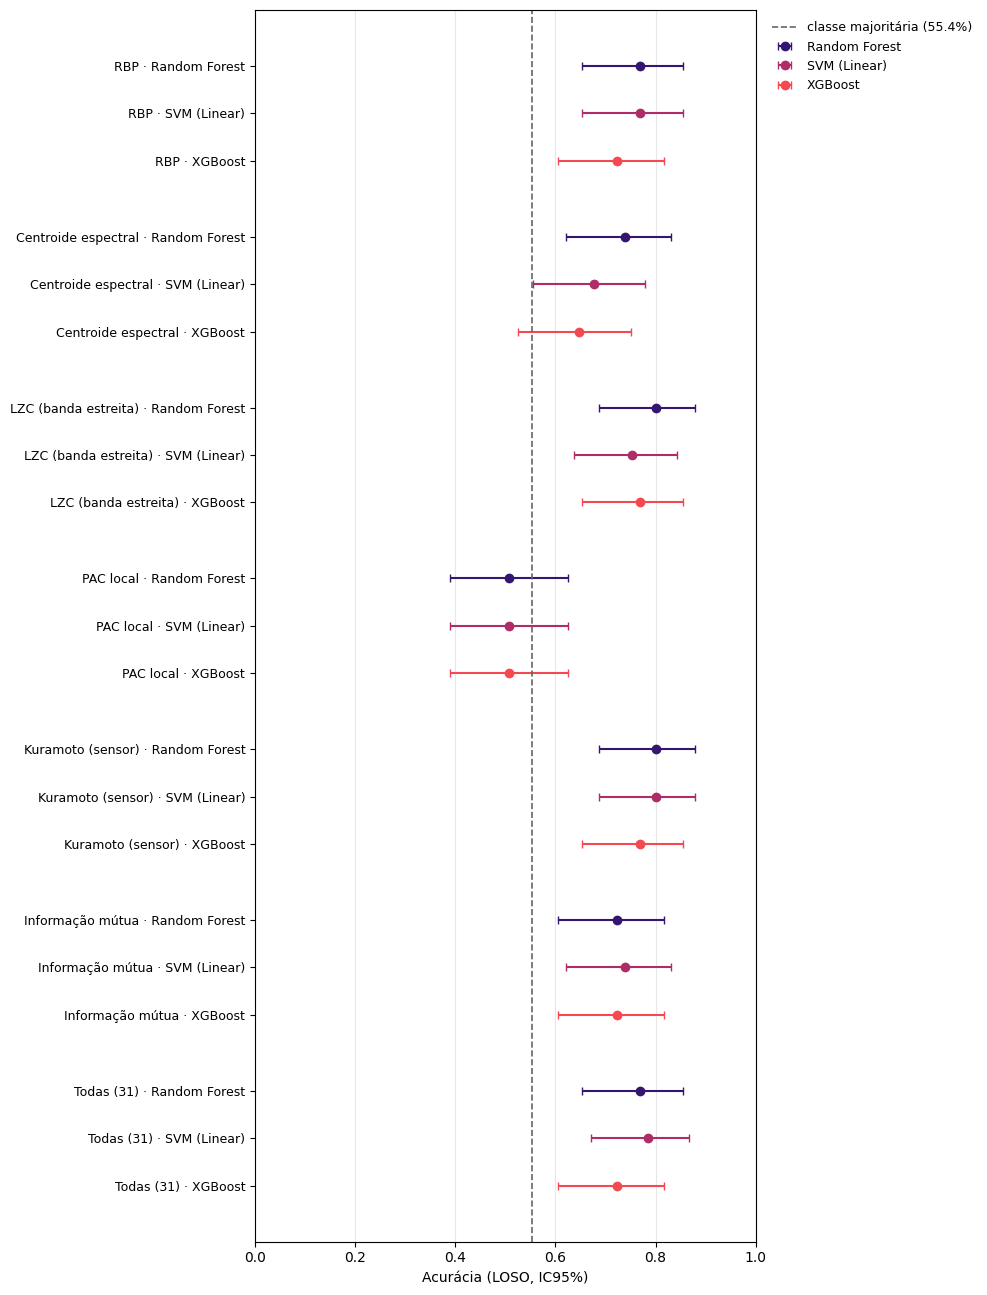

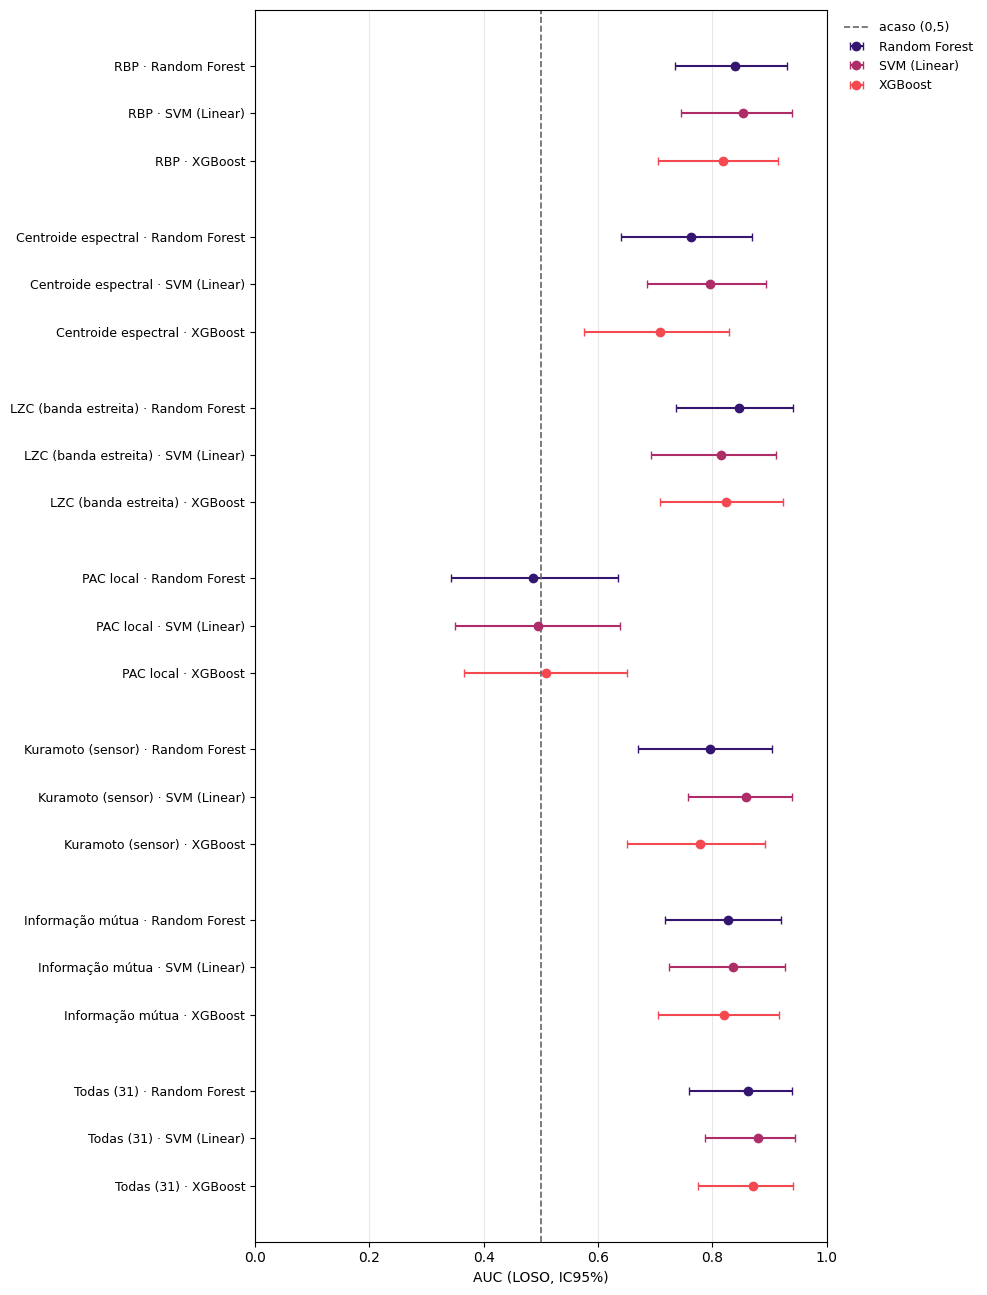

In [7]:
M.plot_performance(results, "Accuracy", FIG_DIR / "desempenho_acuracia.png")
M.plot_performance(results, "AUC", FIG_DIR / "desempenho_auc.png")

MAKE_DASHBOARDS = True
if MAKE_DASHBOARDS:
    for (model, cat), p in preds.groupby(["Modelo", "Categoria"], sort=False):
        M.plot_dashboard(p, model, cat, "images")
    print("painéis salvos em images/")

## 7. Resumo para o README

In [8]:
resumo = M.results_markdown(results, cmp, cov_auc)
Path("resultados_resumo.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Resumo dos resultados (gerado por models_training.ipynb)

Sujeitos: 65. Classe majoritária: 55.4%. IC95%: Wilson (acurácia) e bootstrap estratificado com 2000 réplicas (AUC).

| Modelo | Conjunto | Acurácia | AUC | Sensib. | Especif. |
|---|---|---|---|---|---|
| SVM (Linear) | Todas (31) | 78.5% [67.0%; 86.7%] | 0.880 [0.787; 0.944] | 75.0% | 82.8% |
| XGBoost | Todas (31) | 72.3% [60.4%; 81.7%] | 0.872 [0.775; 0.942] | 72.2% | 72.4% |
| Random Forest | Todas (31) | 76.9% [65.4%; 85.5%] | 0.862 [0.759; 0.938] | 75.0% | 79.3% |
| SVM (Linear) | Kuramoto (sensor) | 80.0% [68.7%; 87.9%] | 0.859 [0.757; 0.939] | 77.8% | 82.8% |
| SVM (Linear) | RBP | 76.9% [65.4%; 85.5%] | 0.853 [0.744; 0.940] | 63.9% | 93.1% |
| Random Forest | LZC (banda estreita) | 80.0% [68.7%; 87.9%] | 0.846 [0.736; 0.941] | 83.3% | 75.9% |
| Random Forest | RBP | 76.9% [65.4%; 85.5%] | 0.840 [0.735; 0.930] | 77.8% | 75.9% |
| SVM (Linear) | Informação mútua | 73.8% [62.0%; 83.0%] | 0.836 [0.723; 0.926] | 69.4% | 79.3% |
| Random Forest | Informação mútua | 72.3% [60.4%; 81.7%] | 0.828 [0.717; 0.919] | 77.8% | 65.5% |
| XGBoost | LZC (banda estreita) | 76.9% [65.4%; 85.5%] | 0.824 [0.709; 0.922] | 83.3% | 69.0% |
| XGBoost | Informação mútua | 72.3% [60.4%; 81.7%] | 0.820 [0.704; 0.916] | 77.8% | 65.5% |
| XGBoost | RBP | 72.3% [60.4%; 81.7%] | 0.819 [0.705; 0.915] | 72.2% | 72.4% |
| SVM (Linear) | LZC (banda estreita) | 75.4% [63.7%; 84.2%] | 0.814 [0.693; 0.912] | 72.2% | 79.3% |
| SVM (Linear) | Centroide espectral | 67.7% [55.6%; 77.8%] | 0.796 [0.685; 0.893] | 63.9% | 72.4% |
| Random Forest | Kuramoto (sensor) | 80.0% [68.7%; 87.9%] | 0.795 [0.670; 0.903] | 77.8% | 82.8% |
| XGBoost | Kuramoto (sensor) | 76.9% [65.4%; 85.5%] | 0.779 [0.650; 0.892] | 80.6% | 72.4% |
| Random Forest | Centroide espectral | 73.8% [62.0%; 83.0%] | 0.762 [0.640; 0.868] | 75.0% | 72.4% |
| XGBoost | Centroide espectral | 64.6% [52.5%; 75.1%] | 0.708 [0.575; 0.829] | 66.7% | 62.1% |
| XGBoost | PAC local | 50.8% [38.9%; 62.5%] | 0.510 [0.366; 0.651] | 55.6% | 44.8% |
| SVM (Linear) | PAC local | 50.8% [38.9%; 62.5%] | 0.494 [0.350; 0.639] | 63.9% | 34.5% |
| Random Forest | PAC local | 50.8% [38.9%; 62.5%] | 0.486 [0.343; 0.635] | 61.1% | 37.9% |

## Comparações (McNemar exato)

| Modelo | Tipo | A | B | Acc A | Acc B | só A acerta | só B acerta | p | p Holm |
|---|---|---|---|---|---|---|---|---|---|
| Random Forest | primária | Todas (31) | RBP | 0.769 | 0.769 | 3 | 3 | 1.0000 | 1.0000 |
| Random Forest | secundária (exploratória) | Todas (31) | Kuramoto (sensor) | 0.769 | 0.800 | 4 | 6 | 0.7539 |  |
| SVM (Linear) | primária | Todas (31) | RBP | 0.785 | 0.769 | 7 | 6 | 1.0000 | 1.0000 |
| SVM (Linear) | secundária (exploratória) | Todas (31) | Kuramoto (sensor) | 0.785 | 0.800 | 5 | 6 | 1.0000 |  |
| XGBoost | primária | Todas (31) | RBP | 0.723 | 0.723 | 8 | 8 | 1.0000 | 1.0000 |
| XGBoost | secundária (exploratória) | Todas (31) | Kuramoto (sensor) | 0.723 | 0.769 | 6 | 9 | 0.6072 |  |

Modelo só com idade e sexo: AUC 0.580 [0.442; 0.725].
